<a href="https://colab.research.google.com/github/Flavio008/-tude-de-sant-publique/blob/master/Crecimiento_econ%C3%B3mico_ARG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Crecimiento económico**
* PIB real por habitante, para observar cómo evoluciona la producción económica por persona.



### **Bienestar social**
* Pobreza y desigualdad, mediante indicadores disponibles para Argentina.



### **Período**
* Desde 1960 hasta el último año disponible para cada indicador. Los datos sociales pueden comenzar más tarde o tener años sin observaciones.

In [2]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

# Indicadores oficiales del Banco Mundial
indicadores = {
    "NY.GDP.PCAP.KD": "PIB_real_por_habitante",
    "SI.POV.NAHC": "Pobreza_linea_nacional_pct",
    "SI.POV.GINI": "Indice_Gini"
}



In [3]:
datos = []

for codigo, nombre in indicadores.items():
    url = (
        "https://api.worldbank.org/v2/country/ARG/indicator/"
        f"{codigo}?date=1960:2025&format=json&per_page=200"
    )

    respuesta = requests.get(url, timeout=30)
    respuesta.raise_for_status()
    resultado = respuesta.json()

    if len(resultado) < 2 or resultado[1] is None:
        print(f"Sin datos disponibles: {nombre}")
        continue

    df = pd.DataFrame([
        {
            "año": int(item["date"]),
            nombre: item["value"]
        }
        for item in resultado[1]
        if item["value"] is not None
    ])

    datos.append(df)



In [4]:
# Combinar los indicadores por año
if not datos:
    raise ValueError("La API no ha devuelto datos.")

base = datos[0]
for df in datos[1:]:
    base = base.merge(df, on="año", how="outer")

base = base.sort_values("año")



In [5]:
# Guardar la base descargada
base.to_csv("argentina_datos_banco_mundial.csv", index=False)

print(base.tail(10))
print("Archivo CSV guardado en:", __import__("os").path.abspath(
    "argentina_datos_banco_mundial.csv"
))



     año  PIB_real_por_habitante  Pobreza_linea_nacional_pct  Indice_Gini
56  2016            13265.886064                        30.3         42.3
57  2017            13520.112985                        25.7         41.4
58  2018            13058.328545                        32.0         41.7
59  2019            12706.397811                        35.5         43.3
60  2020            11393.050596                        42.0         42.7
61  2021            12549.281170                        37.3         42.4
62  2022            13276.823211                        39.2         40.7
63  2023            12993.092887                        41.7         42.4
64  2024            12774.350660                        38.1         42.4
65  2025            13287.115953                        28.2          NaN
Archivo CSV guardado en: /content/argentina_datos_banco_mundial.csv


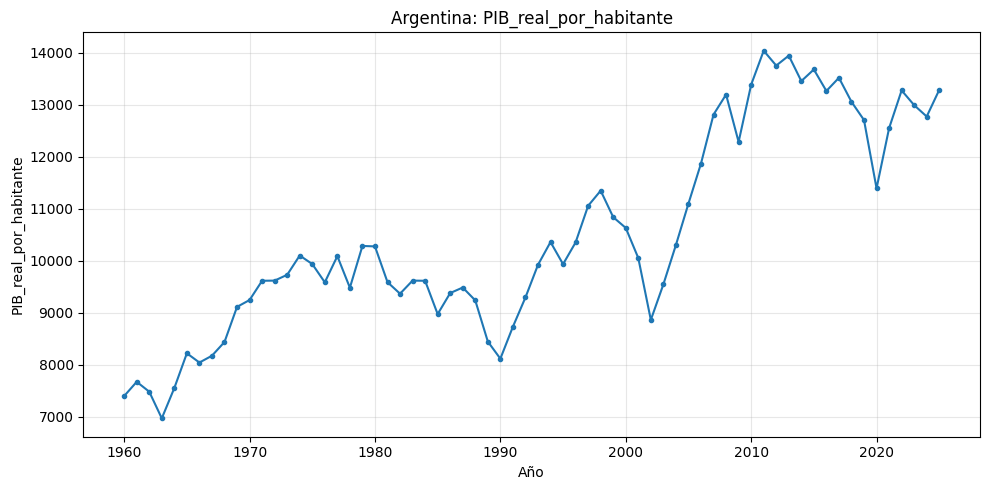

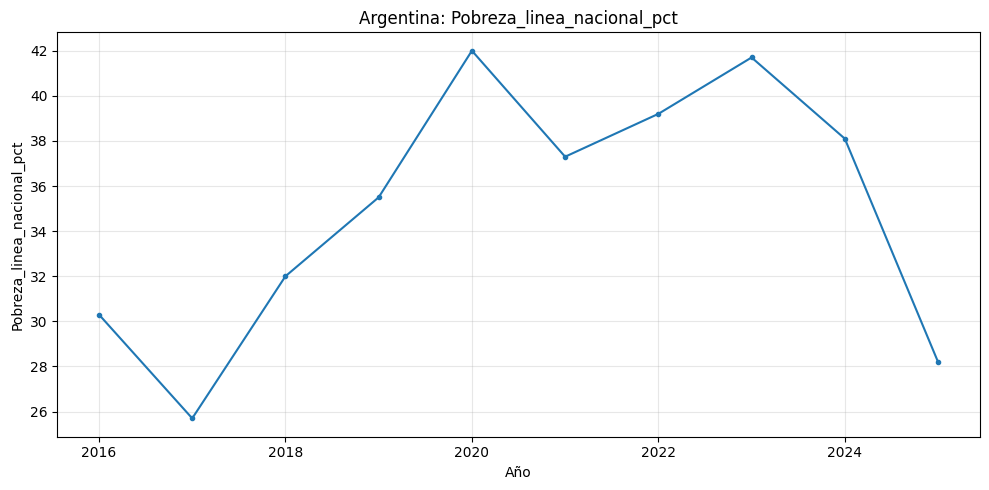

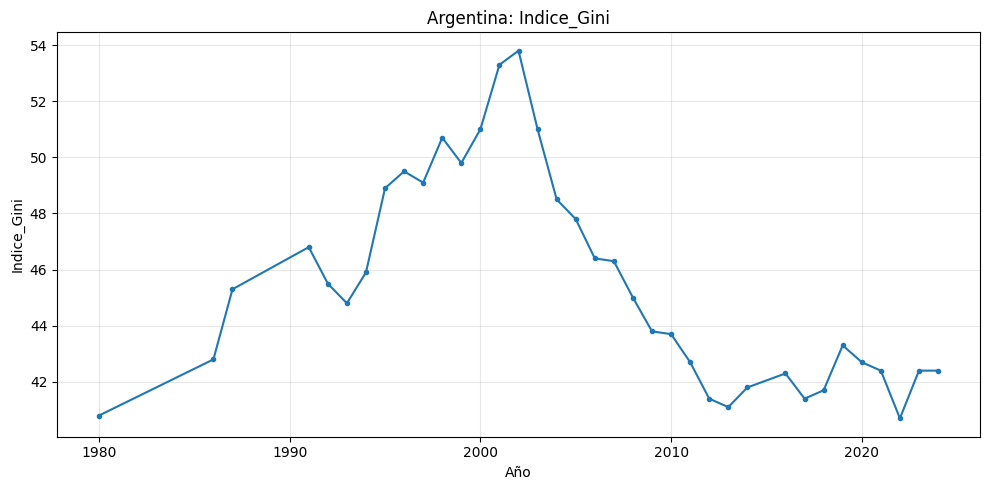

In [6]:
# Graficar cada indicador por separado, porque tienen unidades distintas
for columna in base.columns:
    if columna == "año":
        continue

    serie = base.dropna(subset=[columna])

    if serie.empty:
        continue

    plt.figure(figsize=(10, 5))
    plt.plot(serie["año"], serie[columna], marker=".")
    plt.title(f"Argentina: {columna}")
    plt.xlabel("Año")
    plt.ylabel(columna)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
